<a href="https://colab.research.google.com/github/thunwa2524/nxp_k64F_temperature_measure/blob/main/analyzetemp_uart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

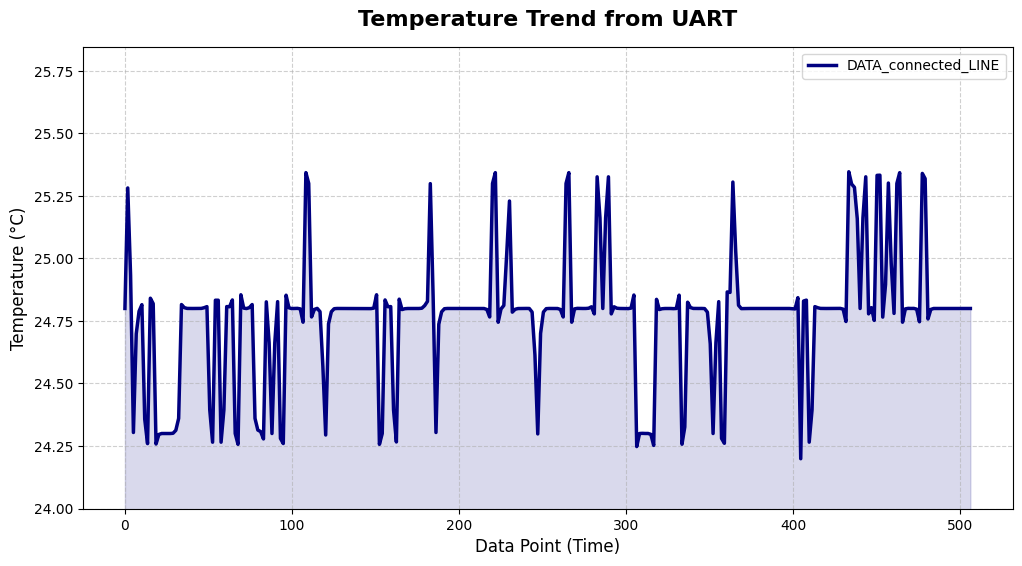

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# ชื่อไฟล์ Log จาก PuTTY
file_name = 'putty_data.txt'

try:
    # 1. อ่านไฟล์และจัดการข้อมูล
    df = pd.read_csv(file_name, header=None, names=['Temperature'])
    df['Temperature'] = pd.to_numeric(df['Temperature'], errors='coerce')
    df = df = df.dropna().reset_index(drop=True)

    # ต้องมีข้อมูลอย่างน้อย 4 จุดถึงจะทำเส้นโค้ง (Cubic Spline) ได้
    if len(df) < 4:
        print("⚠️ ข้อมูลน้อยเกินไปสำหรับการทำเส้นโค้ง (ต้องการอย่างน้อย 4 จุด)")
    else:
        # กำหนดแกน X และ Y จากข้อมูลจริง
        x = df.index
        y = df['Temperature']

        # 2. สร้างจุดจำลองที่ความละเอียดสูง (300 จุด) เพื่อให้เส้นดูสมูท
        x_smooth = np.linspace(x.min(), x.max(), 300)

        # 3. คำนวณเส้นโค้ง (Cubic Spline)
        spline = make_interp_spline(x, y, k=3)
        y_smooth = spline(x_smooth)

        # 4. เริ่มตั้งค่าและพลอตกราฟ
        plt.figure(figsize=(12, 6))

        # พลอตเส้นโค้งสมูท (สีส้ม)
        plt.plot(x_smooth, y_smooth, color='#000080', linewidth=2.5, label='DATA_connected_LINE')

        # ระบายสีจางๆ ใต้กราฟให้ดูมีมิติ
        plt.fill_between(x_smooth, y_smooth, y_smooth.min() - 0.5, color='#000080', alpha=0.15)

        # พลอตจุดข้อมูลจริงทับลงไป (ให้รู้ว่าค่าจริงๆ คือจุดไหน)
        #plt.scatter(x, y, color='#DC143C', s=10, zorder=20, label='Actual Data')

        # ตกแต่งกราฟ
        plt.title('Temperature Trend from UART', fontsize=16, fontweight='bold', pad=15)
        plt.xlabel('Data Point (Time)', fontsize=12)
        plt.ylabel('Temperature (°C)', fontsize=12)

        # จัดขอบล่างของแกน Y ให้สวยงาม (ไม่ลอยเกินไป)
        plt.ylim(bottom=y_smooth.min() - 0.2, top=y_smooth.max() + 0.5)

        plt.grid(True, linestyle='--', alpha=0.6)
        plt.legend(loc='best')

        plt.show()

except Exception as e:
    print("Error:", e)